**FAVORITOS**

In [ ]:
import pandas as pd
import numpy as np
import json

from pathlib import Path

def localizar_edas():
    """Busca Data/raw y Data/processed en Jupyter, Visual Studio Code y Colab.

    Orden de búsqueda: carpeta del notebook, directorio de trabajo y, en Colab, /content.
    Sirve con la estructura Data/raw y Data/processed, y también si los CSV de raw
    o de processed están sueltos en una de esas carpetas (en Colab, junto a sample_data).
    """
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }
    marcas_raw = (
        "artistainfo.json",
        "cancioninfo.json",
        "fecha.json",
        "favoritos.json",
        "listas.json",
        "popularidad.json",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )
    marcas_processed = (
        "cancion.csv",
        "cancion_ids.csv",
        "id_disco.csv",
        "id_genero.csv",
        "fecha_publicacion.csv",
        "fecha_limpio.csv",
        "artistas.csv",
        "artistas_ids.csv",
        "artistas_sql.csv",
        "id_artistas_sql.csv",
        "favoritos.csv",
        "favoritos_eda.csv",
        "listas_canciones.csv",
        "popularidad.csv",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    cwd = Path.cwd().resolve()
    if cwd not in bases:
        bases.append(cwd)
    content = Path("/content")
    if content.is_dir():
        content = content.resolve()
        if content not in bases:
            bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir() and drive not in bases:
            bases.append(drive)

    def buscar(nombre, marcas):
        opuesta = "processed" if nombre == "raw" else "raw"

        def tiene(carpeta):
            try:
                return any((carpeta / marca).is_file() for marca in marcas)
            except OSError:
                return False

        def nombrada(directorio):
            anidada = directorio / "Data" / nombre
            if tiene(anidada):
                return anidada
            if directorio.name == nombre and tiene(directorio):
                return directorio
            return None

        def hijos(directorio, profundidad, limite):
            if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
                return None
            try:
                entradas = list(directorio.iterdir())
            except OSError:
                return None
            for hijo in entradas:
                if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                    continue
                limite[0] -= 1
                hallazgo = nombrada(hijo)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
                hallazgo = hijos(hijo, profundidad - 1, limite)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
            return None

        for base in bases:
            if not base.is_dir():
                continue
            hallazgo = nombrada(base)
            if hallazgo is not None:
                return hallazgo
            for padre in list(base.parents)[:6]:
                hallazgo = nombrada(padre)
                if hallazgo is not None:
                    return hallazgo
            profundidad = 3 if base.name in {"content", "MyDrive"} else 2
            hallazgo = hijos(base, profundidad, [400])
            if hallazgo is not None:
                return hallazgo
            if base.name != opuesta and tiene(base):
                return base
        return None

    cruda = buscar("raw", marcas_raw)
    procesados = buscar("processed", marcas_processed)

    if cruda is None and procesados is None:
        raise FileNotFoundError(
            "No se encuentran los datos. "
            "Tiene que existir la carpeta Data/raw o Data/processed, "
            "o los CSV en la carpeta del notebook, en el directorio de trabajo "
            "o, en Colab, en /content junto a sample_data."
        )

    if cruda is not None and procesados is None:
        if cruda.name == "raw":
            procesados = cruda.parent / "processed"
        else:
            procesados = cruda
        procesados.mkdir(parents=True, exist_ok=True)
    elif procesados is not None and cruda is None:
        if procesados.name == "processed":
            cruda = procesados.parent / "raw"
        else:
            cruda = procesados

    return cruda, procesados
DATA_RAW, DATA_PROCESSED = localizar_edas()
print("Raw:", DATA_RAW)
print("Processed:", DATA_PROCESSED)

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)


In [ ]:
with open(DATA_RAW / "favoritos.json", "r", encoding="utf-8") as file:
    data = json.load(file)


In [ ]:
# Mostrar el contenido del diccionario
data

{'nqp_81': ['blues.00000.wav', 'jazz.00033.wav'],
 'cdm_98': ['blues.00000.wav', 'classical.00028.wav'],
 'ypb_7': ['blues.00000.wav', 'disco.00042.wav', 'hiphop.00089.wav'],
 'qux_5': ['blues.00000.wav', 'hiphop.00086.wav'],
 'fdc_56': ['blues.00000.wav', 'pop.00036.wav'],
 'wix_83': ['blues.00000.wav', 'country.00060.wav', 'jazz.00026.wav'],
 'nir_13': ['blues.00000.wav'],
 'kss_81': ['blues.00000.wav'],
 'lyl_87': ['blues.00000.wav', 'pop.00079.wav', 'rock.00065.wav'],
 'xsm_78': ['blues.00000.wav', 'blues.00033.wav', 'metal.00094.wav'],
 'ruj_62': ['blues.00000.wav'],
 'nhl_90': ['blues.00000.wav', 'country.00031.wav', 'jazz.00039.wav'],
 'kce_50': ['blues.00000.wav',
  'metal.00026.wav',
  'reggae.00029.wav',
  'rock.00013.wav'],
 'ybl_21': ['blues.00000.wav', 'reggae.00035.wav', 'rock.00040.wav'],
 'ksn_45': ['blues.00000.wav'],
 'xyn_43': ['blues.00000.wav'],
 'fir_39': ['blues.00000.wav'],
 'rvw_22': ['blues.00000.wav', 'disco.00037.wav'],
 'jnb_74': ['blues.00000.wav'],
 'dga_

In [ ]:
# Se itera sobre cada usuario y sus canciones favoritas para crear una lista de diccionarios.
rows = []
for cancion, lista in data.items():
    for item_str in lista:
        row_dict = {
            "archivo_cancion": item_str,
            "id_usuario": cancion
        }
        rows.append(row_dict)

In [ ]:
# Crear un DataFrame
df_favoritos=pd.DataFrame(rows)
df_favoritos.head(15)

,archivo_cancion,id_usuario
0,blues.00000.wav,nqp_81
1,jazz.00033.wav,nqp_81
2,blues.00000.wav,cdm_98
3,classical.00028.wav,cdm_98
4,blues.00000.wav,ypb_7
5,disco.00042.wav,ypb_7
6,hiphop.00089.wav,ypb_7
7,blues.00000.wav,qux_5
8,hiphop.00086.wav,qux_5
9,blues.00000.wav,fdc_56


In [ ]:
# Mostrar información resumida del DataFrame 'df_favoritos'.
df_favoritos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1554708 entries, 0 to 1554707
Data columns (total 2 columns):
 #   Column           Non-Null Count    Dtype 
---  ------           --------------    ----- 
 0   archivo_cancion  1554708 non-null  object
 1   id_usuario       1554708 non-null  object
dtypes: object(2)
memory usage: 23.7+ MB


# SUSTICIÓN ARCHIVO CANCION POR ID CANCION FUSIONANDO DF

In [ ]:
df_cancion_id = pd.read_csv(DATA_PROCESSED / "cancion_ids.csv")

df_cancion_id.head()


,cancion,duracion,genero,disco,autor,id_cancion,id_genero,id_disco
0,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1
1,blues.00001.wav,00:02:22,blues,blues7,Sonny Boy Williamson,2,1,2
2,blues.00002.wav,00:01:36,blues,blues5,Muddy Waters,3,1,3
3,blues.00003.wav,00:01:51,blues,blues10,Freddie King,4,1,4
4,blues.00004.wav,00:03:11,blues,blues1,Memphis Minnie,5,1,5


In [ ]:
# Fusión de df_favoritos con df_cancion_id
df_favoritos_merged_final = pd.merge(
    df_favoritos,
    df_cancion_id,
    left_on='archivo_cancion',
    right_on='cancion',
    how='left'
)

print("Primeras 5 filas del DataFrame fusionado:")
display(df_favoritos_merged_final.head())

print("Información del DataFrame fusionado:")
df_favoritos_merged_final.info()

Primeras 5 filas del DataFrame fusionado:


,archivo_cancion,id_usuario,cancion,duracion,genero,disco,autor,id_cancion,id_genero,id_disco
0,blues.00000.wav,nqp_81,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1
1,jazz.00033.wav,nqp_81,jazz.00033.wav,00:00:36,jazz,jazz11,Coleman Hawkins,534,6,110
2,blues.00000.wav,cdm_98,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1
3,classical.00028.wav,cdm_98,classical.00028.wav,00:02:18,classical,classical11,Dmitri Shostakovich,129,2,36
4,blues.00000.wav,ypb_7,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1


Información del DataFrame fusionado:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1554708 entries, 0 to 1554707
Data columns (total 10 columns):
 #   Column           Non-Null Count    Dtype 
---  ------           --------------    ----- 
 0   archivo_cancion  1554708 non-null  object
 1   id_usuario       1554708 non-null  object
 2   cancion          1554708 non-null  object
 3   duracion         1522937 non-null  object
 4   genero           1554708 non-null  object
 5   disco            1554708 non-null  object
 6   autor            1554708 non-null  object
 7   id_cancion       1554708 non-null  int64 
 8   id_genero        1554708 non-null  int64 
 9   id_disco         1554708 non-null  int64 
dtypes: int64(3), object(7)
memory usage: 118.6+ MB


In [ ]:
# Guardamos el trabajo en un archivo CSV. Después lo necesitaremos para limpiar duplicados y hacer el EDA.

output_csv_path = DATA_PROCESSED / "favoritos_eda.csv"
df_favoritos.to_csv(output_csv_path, index=False)


In [ ]:
# Seleccionamos únicamente las columnas 'id_usuario' y 'id_cancion' y las asignamos a df_favoritos.
df_favoritos = df_favoritos_merged_final[['id_usuario', 'id_cancion']]

print("Primeras 5 filas del DataFrame 'df_favoritos' con solo 'id_usuario' e 'id_cancion':")
display(df_favoritos.head())

print("Información del DataFrame 'df_favoritos' filtrado:")
df_favoritos.info()

Primeras 5 filas del DataFrame 'df_favoritos' con solo 'id_usuario' e 'id_cancion':


,id_usuario,id_cancion
0,nqp_81,1
1,nqp_81,534
2,cdm_98,1
3,cdm_98,129
4,ypb_7,1


Información del DataFrame 'df_favoritos' filtrado:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1554708 entries, 0 to 1554707
Data columns (total 2 columns):
 #   Column      Non-Null Count    Dtype 
---  ------      --------------    ----- 
 0   id_usuario  1554708 non-null  object
 1   id_cancion  1554708 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 23.7+ MB


# Comparación detallada del uso de memoria

In [ ]:
print("Uso de memoria de df_favoritos (con id_usuario e id_cancion):")
display(df_favoritos.memory_usage(deep=True))

print("Uso de memoria de df_favoritos_merged_final (original con todas las columnas):")
display(df_favoritos_merged_final.memory_usage(deep=True))

print("Memoria total de df_favoritos:", df_favoritos.memory_usage(deep=True).sum() / (1024**2), "MB")
print("Memoria total de df_favoritos_merged_final:", df_favoritos_merged_final.memory_usage(deep=True).sum() / (1024**2), "MB")

Uso de memoria de df_favoritos (con id_usuario e id_cancion):


Index              132
id_usuario    85353445
id_cancion    12437664
dtype: int64

Uso de memoria de df_favoritos_merged_final (original con todas las columnas):


Index                    132
archivo_cancion    100134143
id_usuario          85353445
cancion            100134143
duracion            87824081
genero              84587063
disco               86918707
autor               95044969
id_cancion          12437664
id_genero           12437664
id_disco            12437664
dtype: int64

Memoria total de df_favoritos: 93.26099491119385 MB
Memoria total de df_favoritos_merged_final: 645.9328413009644 MB


Tras la fusión de los dos dataframes observamos una significativa reducción de espacio sustituyen el nombre de la canción por su ID.

In [ ]:
# Guardamos el trabajo en un archivo CSV. Ahora 'df_favoritos' contiene 'id_usuario' y 'id_cancion'.
# Los datos están en bruto para trabajar con ellos en SQL, como se pide.

output_csv_path = DATA_PROCESSED / "favoritos.csv"
df_favoritos.to_csv(output_csv_path, index=False)


In [ ]:
df_favoritos.count()

id_usuario    1554708
id_cancion    1554708
dtype: int64

#TRATAMIENTO NULOS Y DUPLICADOS

In [ ]:
#Valores nulos en 'df_favoritos'.
# No hay nulos en ninguna de las dos columnas.
df_favoritos.isnull().sum()

id_usuario    0
id_cancion    0
dtype: int64

In [ ]:
# Buscamos duplicados en la relación usuario-cancion.
# Un usuario puede darle favoritos a varias canciones distintas asi como una cancion puede ser guardada en fav por varios usuarios.

registros_duplicados = df_favoritos[df_favoritos.duplicated(subset=['id_usuario', 'id_cancion'],keep=False)].sort_values(['id_usuario', 'id_cancion'])
porcentaje_duplicados = (len(registros_duplicados) / len(df_favoritos)) * 100

display(registros_duplicados)

print(f"Porcentaje de registros duplicados, todas las entradas: {porcentaje_duplicados:.2f}%")


,id_usuario,id_cancion
501624,aap_52,687
501625,aap_52,687
291905,adb_33,104
291906,adb_33,104
139501,agb_59,46
...,...,...
924043,yvp_13,402
248546,yxh_41,90
248547,yxh_41,90
409839,yyn_80,148


Porcentaje de registros duplicados, todas las entradas: 0.14%


Vamos a explorar si estos duplicados responden al algun patrón observando el genero y el disco al que pertenecen estas canciones.

In [ ]:
duplicados_por_genero_disco = (
    df_favoritos_merged_final[
        df_favoritos_merged_final.duplicated(
            subset=['id_usuario', 'id_cancion'],
            keep='first')]
    ['genero']
    .value_counts()
    .reset_index(name='num_duplicados'))

display(duplicados_por_genero_disco)

,genero,num_duplicados
0,reggae,122
1,rock,116
2,blues,110
3,classical,110
4,hiphop,108
5,disco,101
6,pop,101
7,metal,99
8,country,99
9,jazz,95


In [ ]:
duplicados_por_disco = (
    df_favoritos_merged_final[
        df_favoritos_merged_final.duplicated(
            subset=['id_usuario', 'id_cancion'],
            keep='first')]
    ['disco']
    .value_counts()
    .reset_index(name='num_duplicados'))

display(duplicados_por_disco.head(10))

,disco,num_duplicados
0,pop16,18
1,jazz3,17
2,reggae1,17
3,reggae7,17
4,reggae10,15
5,hiphop12,15
6,rock2,15
7,rock5,15
8,classical1,15
9,classical15,14


Al analizar los duplicados, no se observa una concentración clara en un género ni en un disco musical concreto. Los registros duplicados aparecen repartidos de forma bastante homogénea, con diferencias pequeñas entre el valor máximo y el mínimo. Por tanto, esta incidencia parece afectar de forma general a la tabla de favoritos, más que estar asociada a un patrón específico.

In [ ]:
# Esta celda nos ayuda a borrar los duplicados pero manteniendo un registro de cada uno de ellos porque no queremos.
# Aunque PANDAS por defecto deja un registro cuando hacemos el drop, me parecia interesante ejecutar este código porque nos muestra
# cuántos se quedan después del borrado, en este caso teniamos 2122 registros repetidos y después de borrar 1061, justo la mitad.
# Esto nos ayudará a sacar conclusiones posteriores.

registros_duplicados.drop_duplicates(subset=['id_usuario', 'id_cancion'], keep='first', inplace=True)

porcentaje_duplicados = (len(registros_duplicados) / len(df_favoritos)) * 100

display(registros_duplicados)

print(f"Porcentaje real de registros duplicados: {porcentaje_duplicados:.2f}%")

,id_usuario,id_cancion
501624,aap_52,687
291905,adb_33,104
139501,agb_59,46
129485,ahj_97,44
2971,ahp_28,1
...,...,...
868991,yuv_93,538
758801,yuy_53,923
924042,yvp_13,402
248546,yxh_41,90


Porcentaje real de registros duplicados: 0.07%


In [ ]:
# Eliminar los duplicados directamente de df_favoritos
df_favoritos = df_favoritos.drop_duplicates(subset=['id_usuario', 'id_cancion'], keep='first').copy()

print("Primeras 5 filas del DataFrame 'df_favoritos' después de la eliminación de duplicados:")
display(df_favoritos.head())

Primeras 5 filas del DataFrame 'df_favoritos' después de la eliminación de duplicados:


,id_usuario,id_cancion
0,nqp_81,1
1,nqp_81,534
2,cdm_98,1
3,cdm_98,129
4,ypb_7,1


In [ ]:
df_favoritos.count()

id_usuario    1553647
id_cancion    1553647
dtype: int64

In [ ]:
print(f"Número de duplicados después de la eliminación: {registros_duplicados.duplicated(subset=['id_usuario', 'id_cancion']).sum()}")

Número de duplicados después de la eliminación: 0


En resumen, las 2122 filas eran todas las apariciones de los registros duplicados, un 0.14% sobre el total. Tras eliminar los duplicados nos quedamos con una aparición de cada relacion duplicada usuario-cancion, son 1061, justo la mitad del total de duplicados, por lo tanto el porcentaje real de entradas sobrantes es 0.07%
El hecho de que 2122 / 1061 sea la mitad sugiere que, en promedio, cada registro duplicado aparecía dos veces. Al no ser muy recurrente para un mismo usuario(solo se repite una vez cada uno) además de estar repartidos los duplicados por canciones de cualquiera de los géneros y distintos discos sin responder a un patrón claro y teniendo en cuenta que son 1061 repetidos en un DF de 1,5M de entradas, esta duplicidad se valora como un error que podemos eliminar.
A nivel de negocio una relación usuario-cancion repetida, no tiene ningún sentido, porque no es posible que un mismo usuario guarde la misma cancion varias veces en favoritos. De esta manera se toma la decisión de eliminar los registros repetidos para continuar con el analisis exploratorio.

In [ ]:
# Verificar el número de duplicados restantes en el DataFrame limpio
num_duplicados_final = df_favoritos.duplicated(subset=['id_usuario', 'id_cancion']).sum()
print(f"Número de duplicados después de la limpieza: {num_duplicados_final}")

Número de duplicados después de la limpieza: 0


In [ ]:
# Mostrar el DataFrame final 'df_favoritos' que contiene únicamente los IDs de usuario y los IDs de canción.

df_favoritos

,id_usuario,id_cancion
0,nqp_81,1
1,nqp_81,534
2,cdm_98,1
3,cdm_98,129
4,ypb_7,1
...,...,...
1554703,ysm_35,1000
1554704,hhj_16,1000
1554705,wdc_70,1000
1554706,agf_66,1000


# (EDA) ANALISIS EXPLORATORIO TABLA FAVORITOS.

Para enriquecer el EDA se fusiona la tabla de favoritos ya sin duplicados para unirla a la tabla de canción donde aparecen más registros.

In [ ]:
df_favoritos_eda = df_favoritos.merge(df_cancion_id[['id_cancion', 'genero', 'disco', 'autor']],on='id_cancion',how='left')
df_favoritos_eda.head()

,id_usuario,id_cancion,genero,disco,autor
0,nqp_81,1,blues,blues4,Stevie Ray Vaughan
1,nqp_81,534,jazz,jazz11,Coleman Hawkins
2,cdm_98,1,blues,blues4,Stevie Ray Vaughan
3,cdm_98,129,classical,classical11,Dmitri Shostakovich
4,ypb_7,1,blues,blues4,Stevie Ray Vaughan


In [ ]:
# TOP 10 canciones más añadidas a favoritos junto a su género.
top_canciones_favoritas = (df_favoritos_eda[['id_cancion','genero']].value_counts().reset_index())

top_canciones_favoritas.columns = ['id_cancion', 'genero', 'num_favoritos']

top_canciones_favoritas.head(10)

,id_cancion,genero,num_favoritos
0,341,disco,2993
1,850,reggae,2993
2,788,pop,2990
3,825,reggae,2986
4,56,blues,2985
5,197,classical,2978
6,129,classical,2975
7,575,jazz,2975
8,365,disco,2971
9,512,jazz,2970


In [ ]:
# Número de veces que canciones han sido añadidas a favoritos agrupadas por género.
favoritos_por_genero = df_favoritos_eda['genero'].value_counts().reset_index()
favoritos_por_genero.columns = ['genero', 'num_favoritos']
favoritos_por_genero

,genero,num_favoritos
0,pop,173618
1,reggae,165317
2,classical,163998
3,rock,154438
4,metal,153318
5,country,151891
6,blues,150998
7,hiphop,150998
8,disco,147032
9,jazz,142039


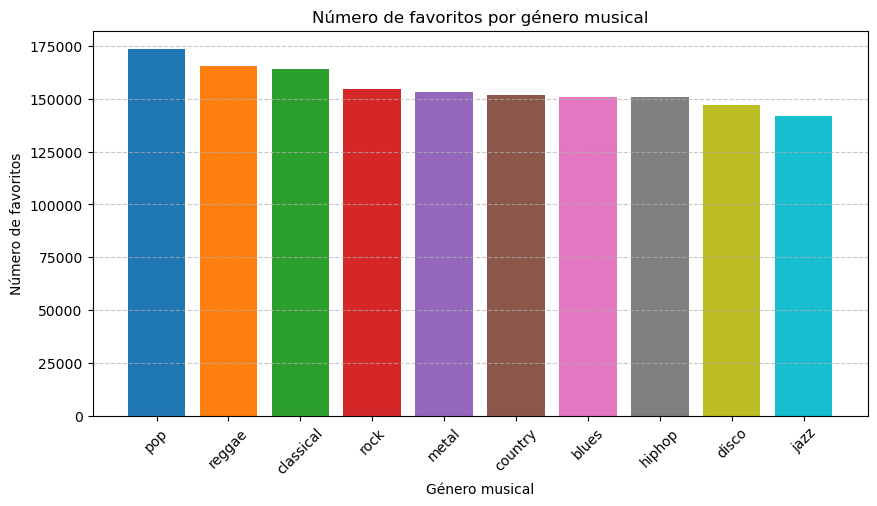

In [ ]:
import matplotlib.pyplot as plt

# Creamos un color distinto para cada género
colores = plt.cm.tab10.colors[:len(favoritos_por_genero)]

plt.figure(figsize=(10, 5))

plt.bar(
    favoritos_por_genero['genero'],
    favoritos_por_genero['num_favoritos'],
    color=colores
)

plt.title('Número de favoritos por género musical')
plt.xlabel('Género musical')
plt.ylabel('Número de favoritos')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

En esta primera muestra vemos como en el top 10 canciones más añadidas a favoritos esta representado por 7 géneros distintos. Quedan fuera de este ranking los géneros hip-hop, country y metal. Llama la atención que estos 3 géneros a pesar de no aparecer en el top 10, posteriormente en el gráfico de número de favoritos por género, no se encuentran entre los que tienen menos canciones añadidas a favoritos, más bien se sitúan en una posición intermedia dentro de la clasificación.
El reparto de canciones favoritas entre los géneros es muy variado, lo que indica que a pesar de la diferencia entre por ejemplo pop y jazz que están a la cabeza y a al cola respectivamente el abanico de selección musical entre usuarios es enorme.

Vamos a hacer a sacar otra muestra para tener un sondeo con más datos.





In [ ]:
# TOP 20 canciones más añadidas a favoritos junto a su género.
top_canciones_favoritas = (df_favoritos_eda[['id_cancion','genero']].value_counts().reset_index())

top_canciones_favoritas.columns = ['id_cancion', 'genero', 'num_favoritos']
top_canciones_favoritas.head(20)

,id_cancion,genero,num_favoritos
0,341,disco,2993
1,850,reggae,2993
2,788,pop,2990
3,825,reggae,2986
4,56,blues,2985
5,197,classical,2978
6,129,classical,2975
7,575,jazz,2975
8,365,disco,2971
9,512,jazz,2970


In [ ]:
# Contar la cantidad de canciones favoritas por usuario, mostrando los 10 primeros en este caso.
usuarios_mas_favoritas = df_favoritos['id_usuario'].value_counts()
print("Top 10 usuarios con más canciones añadidas a favoritos:")
display(usuarios_mas_favoritas.head(10))

Top 10 usuarios con más canciones añadidas a favoritos:


id_usuario
ivk_58    9
wfs_98    8
syh_95    8
bcf_15    8
jts_66    8
wtv_9     8
xke_59    8
ayy_86    8
yqq_59    8
oqn_17    8
Name: count, dtype: int64

In [ ]:
# Calcular la media de canciones favoritas por usuario
media_canciones_por_usuario = df_favoritos['id_usuario'].value_counts().mean()
print(f"La media de canciones añadidas a favoritos por usuario es: {media_canciones_por_usuario:.2f}")

La media de canciones añadidas a favoritos por usuario es: 1.58


In [ ]:
# Contar cuántas canciones ha añadido cada usuario a favoritos
conteo_canciones_por_usuario = df_favoritos['id_usuario'].value_counts()

# Contar cuántos usuarios tienen 1, 2, 3... hasta 9 canciones favoritas
distribucion_canciones_favoritas = conteo_canciones_por_usuario.value_counts().sort_index().reset_index(name='num_usuarios')
distribucion_canciones_favoritas.columns = ['num_canciones_favoritas', 'num_usuarios']

print("Distribución de usuarios por número de canciones favoritas:")
display(distribucion_canciones_favoritas.head(9))

Distribución de usuarios por número de canciones favoritas:


,num_canciones_favoritas,num_usuarios
0,1,575420
1,2,285416
2,3,95108
3,4,23343
4,5,4616
5,6,776
6,7,118
7,8,16
8,9,1


In [ ]:
correlacion = distribucion_canciones_favoritas[
    'num_canciones_favoritas'
].corr(
    distribucion_canciones_favoritas['num_usuarios']
)

print(f"Correlación entre número de canciones favoritas y número de usuarios: {correlacion:.4f}")

Correlación entre número de canciones favoritas y número de usuarios: -0.7760


# Gráfico de Líneas de la distribución de Canciones Favoritas por Usuario

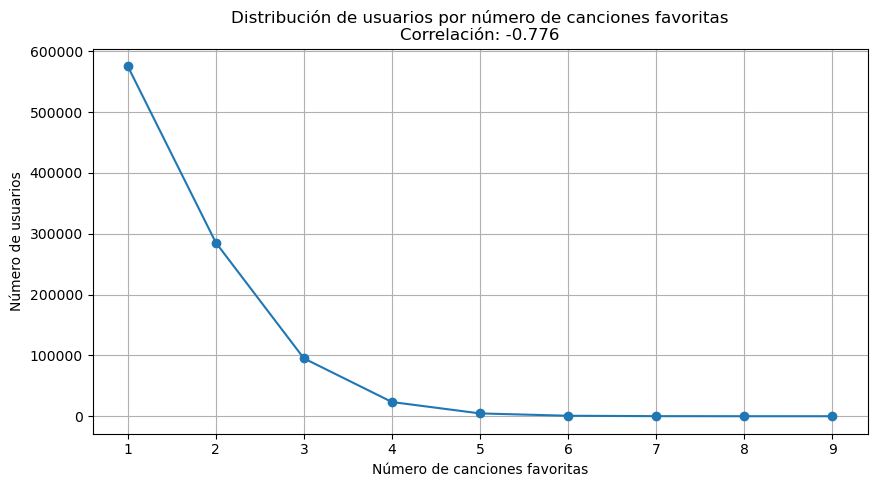

In [ ]:
import matplotlib.pyplot as plt
correlacion = distribucion_canciones_favoritas['num_canciones_favoritas'].corr(
    distribucion_canciones_favoritas['num_usuarios']
)

plt.figure(figsize=(10, 5))

plt.plot(
    distribucion_canciones_favoritas['num_canciones_favoritas'],
    distribucion_canciones_favoritas['num_usuarios'],
    marker='o'
)

plt.title(f'Distribución de usuarios por número de canciones favoritas\nCorrelación: {correlacion:.3f}')
plt.xlabel('Número de canciones favoritas')
plt.ylabel('Número de usuarios')
plt.grid(True)
plt.show()

#Conclusiones

**CONCLUSIÓN:**
Observamos que una gran parte de usuarios únicamente añade una canción o dos a favoritos. A medida que el número de canciones guardadas en favoritos aumenta el número de usuario desciende muy significativamente como demuestra la correlación calculada. Teniendo en cuenta que la función principal de guardar una canción en favoritos suele ser para tener un acceso más rápido a canciones que nos gustan y escuchamos frecuentemente, este análisis puede ser indicativo de que los usuarios utilizan el apartado favoritos de forma puntual para guardar canciones concretas de interés.